In [35]:
import sys
sys.path.append("../src")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA as SkPCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from pca import PCA

In [36]:
digits = load_digits()
X, y = digits.data, digits.target
print(X.shape, y.shape)
print(X[0])

(1797, 64) (1797,)
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


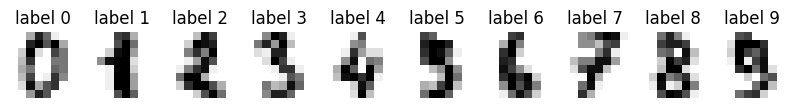

In [37]:
fig, axes = plt.subplots(1, 10, figsize=(10, 2.5))
for ax, img, label in zip(axes, digits.images[:10], y[:10]):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(f"label {label}")
    ax.axis('off')
plt.show()    

## My PCA on a tiny example

In [38]:
X_toy = np.array([[2, 1], [1, 2], [-1, -2], [-2, -1]], dtype=float)
p = PCA(n_components=1).fit(X_toy)
Y_toy = p.transform(X_toy)
print("explained variance:", p.explained_variance_)
print("direction:\n", p.components_)
print("new numbers:\n", Y_toy)
print("rebuilt:\n", p.inverse_transform(Y_toy))

explained variance: [6.]
direction:
 [[0.70710678]
 [0.70710678]]
new numbers:
 [[ 2.12132034]
 [ 2.12132034]
 [-2.12132034]
 [-2.12132034]]
rebuilt:
 [[ 1.5  1.5]
 [ 1.5  1.5]
 [-1.5 -1.5]
 [-1.5 -1.5]]


## Check against scikit-learn

In [39]:
mine = PCA(n_components=10)
Z_mine = mine.fit_transform(X)

sk = SkPCA(n_components=10)
Z_sk = sk.fit_transform(X)

print(Z_mine.shape, Z_sk.shape)
print(np.allclose(mine.explained_variance_, sk.explained_variance_))
print(np.allclose(mine.explained_variance_ratio_, sk.explained_variance_ratio_))
print(np.allclose(np.abs(Z_mine), np.abs(Z_sk)))
print(np.allclose(np.abs(mine.components_.T), np.abs(sk.components_)))

(1797, 10) (1797, 10)
True
True
True
True


## How many components to keep?

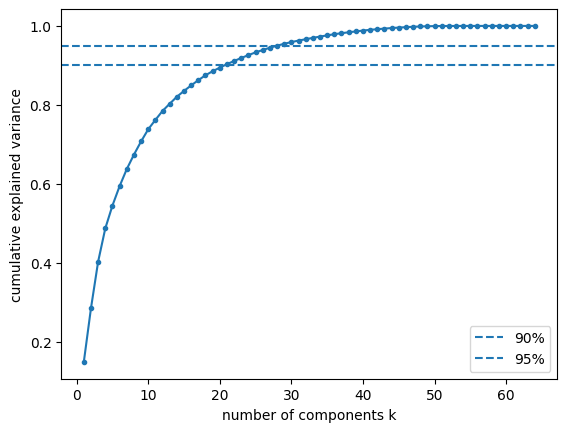

21 29


In [40]:
full = PCA(n_components=64).fit(X)
cum = np.cumsum(full.explained_variance_ratio_)

plt.plot(range(1, 65), cum, marker="o", markersize=3)
plt.axhline(0.90, linestyle="--", label="90%")
plt.axhline(0.95, linestyle="--", label="95%")
plt.xlabel("number of components k")
plt.ylabel("cumulative explained variance")
plt.legend()
plt.savefig("../images/explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

k90 = np.argmax(cum >= 0.90) + 1
k95 = np.argmax(cum >= 0.95) + 1
print(k90, k95)

(1797, 64) (1797, 21) (1797, 64)


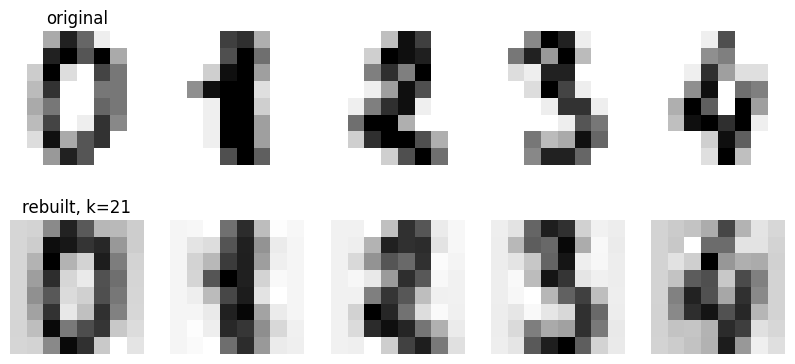

In [41]:
pca21 = PCA(n_components=21).fit(X)
Y21 = pca21.transform(X)
X_back = pca21.inverse_transform(Y21)
print(X.shape, Y21.shape, X_back.shape)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i in range(5):
    axes[0, i].imshow(X[i].reshape(8, 8), cmap='gray_r')
    axes[1, i].imshow(X_back[i].reshape(8, 8), cmap='gray_r')
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_title("original")
axes[1, 0].set_title("rebuilt, k=21")

plt.savefig("../images/rebuilt_digits_k21.png", dpi=150, bbox_inches="tight")
plt.show()

## Does PCA hurt a classifier?

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
print(X_train.shape, X_test.shape)

(1437, 64) (360, 64)


In [43]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
ks = [2, 5, 10, 21, 29, 40, 64]
results = {k: [] for k in ks}
baseline = []

for tr_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]

    base = LogisticRegression(max_iter=5000).fit(X_tr, y_tr)
    baseline.append(base.score(X_val, y_val))

    for k in ks:
        pca = PCA(n_components=k)
        Z_tr = pca.fit_transform(X_tr)
        Z_val = pca.transform(X_val)
        clf = LogisticRegression(max_iter=5000).fit(Z_tr, y_tr)
        results[k].append(clf.score(Z_val, y_val))

print("no PCA", round(np.mean(baseline), 3), round(np.std(baseline), 3))
for k in ks:
    print(k, round(np.mean(results[k]), 3), round(np.std(results[k]), 3))

no PCA 0.96 0.01
2 0.598 0.01
5 0.856 0.021
10 0.922 0.01
21 0.944 0.016
29 0.952 0.009
40 0.961 0.009
64 0.961 0.011


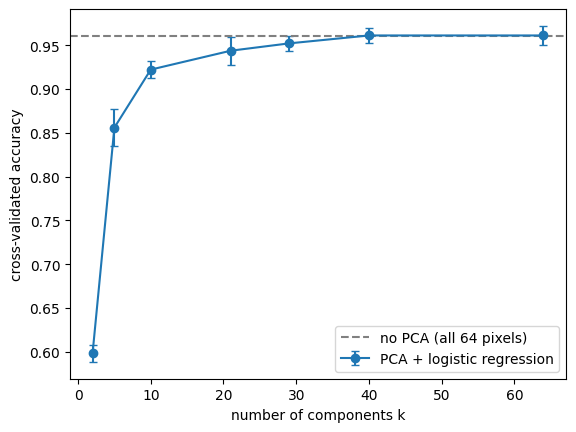

In [44]:
means = [np.mean(results[k]) for k in ks]
stds = [np.std(results[k]) for k in ks]

plt.errorbar(ks, means, yerr=stds, marker='o', capsize=3, label='PCA + logistic regression')

plt.axhline(np.mean(baseline), linestyle="--", color="gray",
            label="no PCA (all 64 pixels)")
plt.xlabel("number of components k")
plt.ylabel("cross-validated accuracy")
plt.legend()
plt.savefig("../images/accuracy_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()


## Final check on the test set

In [45]:
base_test = LogisticRegression(max_iter=5000).fit(X_train, y_train).score(X_test, y_test)

pca = PCA(n_components=29)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)
pca_test = LogisticRegression(max_iter=5000).fit(Z_train, y_train).score(Z_test, y_test)

print("no PCA:", round(base_test, 3))
print("k = 29:", round(pca_test, 3))

no PCA: 0.958
k = 29: 0.953
